Required Packages

In [5]:
import numpy as np
import pandas as pd
import pulp
import matplotlib.pyplot as plt

In [2]:
products = ['P1','P2']
price = [300, 250]
man_hours = [2, 1]
machine_time = [1, 3]

# man hours <= 40 
# machine time <= 45
# P1 amount <= 12

In [3]:
def solve_prod_mix(products, price, man_hours, machine_time):
    model = pulp.LpProblem("Production Mix", pulp.LpMaximize)

    # x_i = amount of product i to produce
    x = model.add_variable_dict("x", products, lowBound=0)

    # Objective: total profit from selling the products
    model += pulp.lpSum(price[i] * x[products[i]] for i in range(len(products)))

    # Constraints
    model += pulp.lpSum(man_hours[i] * x[products[i]] for i in range(len(products))) <= 40, "ManHours"
    model += pulp.lpSum(machine_time[i] * x[products[i]] for i in range(len(products))) <= 45, "MachineTime"
    model += x['P1'] <= 12, "P1Limit"

    result = model.solve(pulp.HiGHS(msg=False))

    if result.status_str == 'Optimal':
        production_plan = {product: x[product].value() for product in products}
        total_profit = pulp.value(model.objective)
        return production_plan, total_profit
    else:
        return None, None

In [ ]:
prod_plan, profit = solve_prod_mix(products, price, man_hours, machine_time)
if prod_plan:
    print("Optimal Production Plan:", prod_plan)
    print("Total Profit:", profit)

Optimal Production Plan: {'P1': 12.0, 'P2': 11.0}
Total Profit: 6350.0


c:\Users\stefa\VS_code projects\Operations-Research\.venv\Lib\site-packages\pulp\core\lp_problem.py:49: UserWarning: Spaces are not permitted in the name. Converted to '_'
  warnings.warn("Spaces are not permitted in the name. Converted to '_'")


Graphical Solution

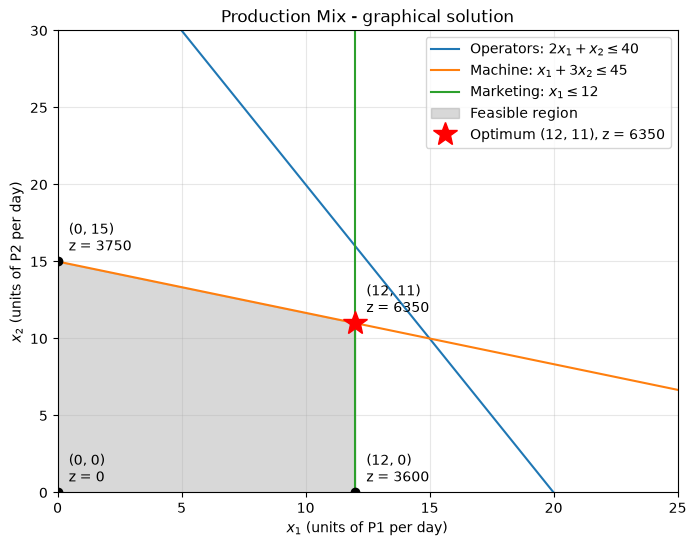

In [7]:
x1 = np.linspace(0, 25, 400)

# Each constraint written as x2 = ... (its boundary line)
operators = 40 - 2 * x1          # 2*x1 + x2 <= 40
machine = (45 - x1) / 3          # x1 + 3*x2 <= 45

fig, ax = plt.subplots(figsize=(8, 6))

# 1. Constraint boundary lines
ax.plot(x1, operators, label=r"Operators: $2x_1 + x_2 \leq 40$")
ax.plot(x1, machine, label=r"Machine: $x_1 + 3x_2 \leq 45$")
ax.axvline(12, color="tab:green", label=r"Marketing: $x_1 \leq 12$")

# 2. Feasible region: below both lines, left of x1 = 12, and x1, x2 >= 0
x1_feasible = np.linspace(0, 12, 200)
upper = np.minimum(40 - 2 * x1_feasible, (45 - x1_feasible) / 3)
ax.fill_between(x1_feasible, 0, upper, color="grey", alpha=0.3, label="Feasible region")

# 3. Corner points of the feasible region and the income at each
corners = [(0, 0), (12, 0), (12, 11), (0, 15)]
for cx, cy in corners:
    z = 300 * cx + 250 * cy
    ax.plot(cx, cy, "ko")
    ax.annotate(f"({cx}, {cy})\nz = {z}", (cx, cy), textcoords="offset points", xytext=(8, 8))

ax.plot(12, 11, "r*", markersize=18, label="Optimum (12, 11), z = 6350")

ax.set_xlim(0, 25)
ax.set_ylim(0, 30)
ax.set_xlabel("$x_1$ (units of P1 per day)")
ax.set_ylabel("$x_2$ (units of P2 per day)")
ax.set_title("Production Mix - graphical solution")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.show()